In [3]:
import pandas as pd
import pylab as pl
import numpy as np
import scipy.optimize as opt
from sklearn import preprocessing 
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import warnings 
warnings.filterwarnings('ignore')

In [4]:
import os 
os.chdir("/Users/lleid/Downloads")
#"C:\Users\lleid\Downloads\recursos_humanos.csv"
cell_df = pd.read_csv("cell_samples.csv")
cell_df

,ID,Clump,UnifSize,UnifShape,MargAdh,SingEpiSize,BareNuc,BlandChrom,NormNucl,Mit,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2
...,...,...,...,...,...,...,...,...,...,...,...
694,776715,3,1,1,1,3,2,1,1,1,2
695,841769,2,1,1,1,2,1,1,1,1,2
696,888820,5,10,10,3,7,3,8,10,2,4
697,897471,4,8,6,4,3,4,10,6,1,4


In [5]:
cell_df["Class"] = cell_df["Class"].replace([2],0)  #Tumor benigno
cell_df["Class"] = cell_df["Class"].replace([4],1)  #Tumor maligno
cell_df

,ID,Clump,UnifSize,UnifShape,MargAdh,SingEpiSize,BareNuc,BlandChrom,NormNucl,Mit,Class
0,1000025,5,1,1,1,2,1,3,1,1,0
1,1002945,5,4,4,5,7,10,3,2,1,0
2,1015425,3,1,1,1,2,2,3,1,1,0
3,1016277,6,8,8,1,3,4,3,7,1,0
4,1017023,4,1,1,3,2,1,3,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...
694,776715,3,1,1,1,3,2,1,1,1,0
695,841769,2,1,1,1,2,1,1,1,1,0
696,888820,5,10,10,3,7,3,8,10,2,1
697,897471,4,8,6,4,3,4,10,6,1,1


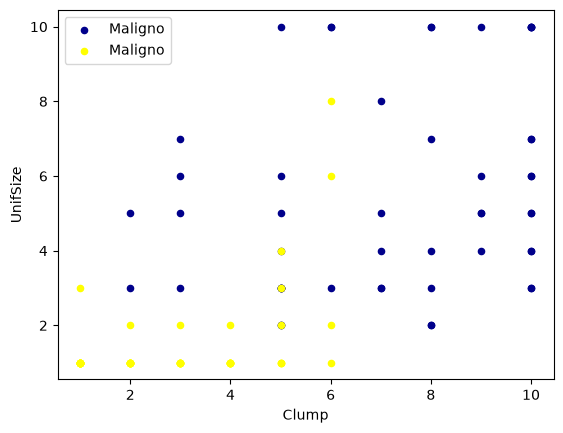

In [6]:
ax = cell_df[cell_df["Class"] == 1][0:50].plot(kind="scatter", x="Clump", y="UnifSize", color="DarkBlue", label="Maligno");
ax = cell_df[cell_df["Class"] == 0][0:50].plot(kind="scatter", x="Clump", y="UnifSize", color="Yellow", label="Maligno", ax=ax)
plt.show()

In [7]:
# Pre-Precesamiento de datos y seloección 
cell_df.dtypes

ID             int64
Clump          int64
UnifSize       int64
UnifShape      int64
MargAdh        int64
SingEpiSize    int64
BareNuc          str
BlandChrom     int64
NormNucl       int64
Mit            int64
Class          int64
dtype: object

In [8]:
# Eliminación de renglones no numéricos en BareNuc
cell_df = cell_df[pd.to_numeric(cell_df["BareNuc"], errors = "coerce").notnull()]
cell_df["BareNuc"] = cell_df["BareNuc"].astype("int")
cell_df.dtypes

ID             int64
Clump          int64
UnifSize       int64
UnifShape      int64
MargAdh        int64
SingEpiSize    int64
BareNuc        int64
BlandChrom     int64
NormNucl       int64
Mit            int64
Class          int64
dtype: object

In [9]:
feature_df = cell_df[["Clump", "UnifSize", "UnifShape", "MargAdh", "SingEpiSize", "BareNuc", "BlandChrom", "NormNucl", "Mit"]]
X = np.asarray(feature_df)
X[0:5]

array([[ 5,  1,  1,  1,  2,  1,  3,  1,  1],
       [ 5,  4,  4,  5,  7, 10,  3,  2,  1],
       [ 3,  1,  1,  1,  2,  2,  3,  1,  1],
       [ 6,  8,  8,  1,  3,  4,  3,  7,  1],
       [ 4,  1,  1,  3,  2,  1,  3,  1,  1]])

In [10]:
cell_df["Class"] = cell_df["Class"].astype("int")
y = np.asarray(cell_df["Class"])
y[0:5]

array([0, 0, 0, 0, 0])

In [11]:
# Creación de grupos de entrenamiento y prueba 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4)
print("Grupo de entrenamiento", X_train.shape, y_train.shape)
print("Grupo de prueba", X_test.shape, y_test.shape)

Grupo de entrenamiento (546, 9) (546,)
Grupo de prueba (137, 9) (137,)


# Modelación con SVM
Opciones de Kernel (Transformaciones):
    1. Linear 
    2. Polynomial
    3. Radial Basis function (RBF)
    4. Sigmoid

In [12]:
from sklearn import svm
clf = svm.SVC(kernel="rbf")
clf.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [13]:
# Predicción para la base de prueba
yhat = clf.predict(X_test)
yhat[0:5]

array([0, 1, 0, 1, 0])

In [14]:
# Creación de matriz de confusión 
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(X)
cm = confusion_matrix(y_test, yhat)
cm

array([[85,  5],
       [ 0, 47]])

In [15]:
y_test

array([0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       0, 0, 0, 0, 1])

In [16]:
yhat

array([0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1,
       0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       0, 0, 0, 0, 1])

In [17]:
z = y_test - yhat
z

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0, -1, -1,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0])

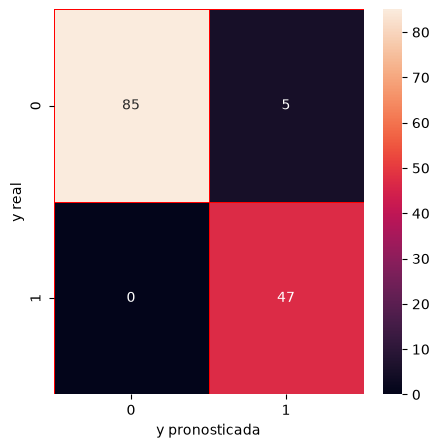

In [22]:
# Visualización de la matriz de confusión 
import seaborn as sns
f, ax = plt.subplots(figsize=(5,5))

sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.show()

# Estadísticas de desempeño

In [24]:
from sklearn.metrics import classification_report
cnf_matrix = confusion_matrix(y_test, yhat, labels=[0,1])
print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       1.00      0.94      0.97        90
           1       0.90      1.00      0.95        47

    accuracy                           0.96       137
   macro avg       0.95      0.97      0.96       137
weighted avg       0.97      0.96      0.96       137



# Determinación de niveles de precisión (Precision)
La Precision ("Precision") = Oorcentaje de predicciones correctas relativas al total de predicciones
* El total se calcula por columna
* Se contesta a la pregunta: ¿Qué porcentaje de las veces que hacemos un pronóstico de cierto tipo éste es correcto?

In [27]:
PrecisionBenigno = cm[0,0] / (cm[0,0] + cm[1,0])
PrecisionBenigno

np.float64(1.0)

In [28]:
PrecisionMaligno = cm[1,1] / (cm[1,1] + cm[0,1])
PrecisionMaligno

np.float64(0.9038461538461539)

# Determinación de niveles de Recuperación (Recall)
La Recuperacion = Porcentaje de predicciones correctas relativas al total de valores reales
* El totalse calcula por renglon
* Se contesta a la pregunta: ¿Qué porcentaje de las veces que se tiene un valor es de indentificarlo?

In [34]:
RecallBenigno = cm[0,0] / (cm[0,0] + cm[0,1]) 
RecallBenigno

np.float64(0.9444444444444444)

In [35]:
RecallMaligno = cm[1,1] / (cm[1,0] + cm[1,1])
RecallMaligno

np.float64(1.0)

# Determinación del Score f1
F1 Score = Media armónica ponderada de la precisión y al recuperación. Cuánto más se acerca a 1, mejor será el modelo.
* F1 Score=2*(Precision * Recall) / (Precision + Recall)

In [36]:
F1Benigno = 2 * (PrecisionBenigno * RecallBenigno) / (PrecisionBenigno + RecallBenigno)
F1Benigno

np.float64(0.9714285714285714)

In [37]:
F1Maligno = 2 * (PrecisionMaligno * RecallMaligno) / (PrecisionMaligno + RecallMaligno)
F1Maligno

np.float64(0.9494949494949495)

# Determinación de soportes
Soporte = Numero de observaviones que pertencen en fomral real a cada clase posible (Total por region)

In [38]:
SoporteBenigno = cm[0,0] + cm[0,1]
SoporteBenigno

np.int64(90)

In [39]:
SoporteMaligno = cm[1,0] + cm[1,1]
SoporteMaligno

np.int64(47)

# Determinación de la Precisión Global (Accuracy)
Acuracy = Porcentaje de predicciones correctas

In [40]:
Correctos = cm[0,0] + cm[1,1]
Incorrectos = cm[0,1] + cm[1,0]
PrecisionGlobal = Correctos / (Correctos + Incorrectos)
PrecisionGlobal

np.float64(0.9635036496350365)

In [41]:
MacroAvgPrecision = (PrecisionBenigno + PrecisionMaligno) / 2
MacroAvgPrecision

np.float64(0.9519230769230769)

In [42]:
MacroAvgRecall = (RecallBenigno + RecallMaligno) / 2
MacroAvgRecall

np.float64(0.9722222222222222)

In [44]:
MacroAvgF1Score = (F1Benigno + F1Maligno) / 2
MacroAvgF1Score

np.float64(0.9604617604617605)

# Promedios ponderados por indicador (Weighted Average)
Promedios ponderados de acuerdo a soportes por indicador

In [45]:
PesoBenigno = SoporteBenigno / (SoporteBenigno + SoporteMaligno)
PesoMaligno = SoporteMaligno / (SoporteBenigno + SoporteMaligno)

In [46]:
WAvgPrecision = PrecisionBenigno * PesoBenigno + PrecisionMaligno * PesoMaligno
WAvgPrecision

np.float64(0.967012914093206)

In [49]:
WAvgRecall = RecallBenigno * PesoBenigno + RecallMaligno * PesoMaligno
WAvgRecall

np.float64(0.9635036496350364)

In [50]:
WAvgF1Score = F1Benigno * PesoBenigno + F1Maligno * PesoMaligno
WAvgF1Score

np.float64(0.9639038982104675)

In [51]:
#Estos valores son los que vamos a encontrar en la tabla que nos da automaticamente la paqueteria 

# Prueba de SVM con Kernel Lineal

In [52]:
from sklearn import svm
clf = svm.SVC(kernel="linear")
clf.fit(X_train, y_train)

yhat = clf.predict(X_test)

#confusion matrix
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(X)
cm = confusion_matrix(y_test, yhat)
cm

array([[85,  5],
       [ 0, 47]])

In [53]:
from sklearn.metrics import classification_report
cnf_matrix = confusion_matrix(y_test, yhat, labels=[0,1])
print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       1.00      0.94      0.97        90
           1       0.90      1.00      0.95        47

    accuracy                           0.96       137
   macro avg       0.95      0.97      0.96       137
weighted avg       0.97      0.96      0.96       137



# Prueba de SVM con Kernel Polinomial

In [54]:
from sklearn import svm
clf = svm.SVC(kernel="poly")
clf.fit(X_train, y_train)

yhat = clf.predict(X_test)

#confusion matrix
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(X)
cm = confusion_matrix(y_test, yhat)
cm

from sklearn.metrics import classification_report
cnf_matrix = confusion_matrix(y_test, yhat, labels=[0,1])
print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       1.00      0.96      0.98        90
           1       0.92      1.00      0.96        47

    accuracy                           0.97       137
   macro avg       0.96      0.98      0.97       137
weighted avg       0.97      0.97      0.97       137

